# Smart Irrigation System: Machine Learning Model Training & Evaluation

## 1. Introduction & Modeling Objectives

This notebook focuses on training, validating, and critically evaluating machine learning classification algorithms to predict the operational state of the irrigation actuator:

$$\text{Target Variable } (y) \in \{0: \text{Pump OFF}, 1: \text{Pump ON}\}$$

### Predictor Features ($X$):
1. **Soil Moisture Resistance (Ohm):** Electrical resistance of the soil matrix (Ω).
2. **Ambient Temperature (deg. C):** Air temperature (°C).
3. **Atmospheric Humidity (%):** Relative ambient air humidity (%).

### Fundamental Methodological Principles:
1. **Actuator State vs Ground-Truth Crop Water Need:** 
   Predicting whether the pump is energized ($y=1$) is an empirical classification of the physical controller's past actuation decisions. It **must not be equated with physiological plant transpiration demand or optimal agronomic irrigation requirements**. The pump status reflects sensor-driven controller logic, which may include calibration biases, threshold heuristics, or controller hysteresis.
2. **Prevention of Data Leakage (Chronological Validation):** 
   Because sequential sensor observations possess high temporal autocorrelation, random cross-validation ($k$-fold) leaks future state information into the past. All model selection employs strictly forward-chaining **`TimeSeriesSplit`**, and the final evaluation is conducted on an unseen **chronological 20% holdout test partition**.
3. **No Synthetic Regression:**
   In compliance with empirical constraints, regression modeling for applied water volume (e.g., liters) is strictly omitted, as no volumetric water flow meter exists in the current sensor payload.


## 2. Environment Setup & Chronological Data Splitting

We load the verified dataset via `src.data_loader` and partition the 5,857 chronological records into:
- **Training Set (80%):** 4,685 records (March 1, 2023 00:00 to April 18, 2023 19:00)
- **Holdout Test Set (20%):** 1,172 records (April 18, 2023 19:15 to May 1, 2023 00:00)


In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 110

# Add project root to sys.path
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.data_loader import load_data
from src.models import (
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    get_chronological_split,
    build_models,
    evaluate_models_cv,
    train_and_evaluate_test,
    run_sensitivity_analysis,
    run_feature_ablation,
    save_artifacts
)

# Load data and partition chronologically
df = load_data()
X_train, X_test, y_train, y_test, train_df, test_df = get_chronological_split(df, test_ratio=0.2)

print(f"Total Dataset Records: {len(df)}")
print(f"Training Partition:    {len(train_df)} rows ({len(train_df)/len(df):.1%}) | {train_df['date'].min()} to {train_df['date'].max()}")
print(f"Test Partition:        {len(test_df)} rows ({len(test_df)/len(df):.1%}) | {test_df['date'].min()} to {test_df['date'].max()}")
print(f"\nTraining Class Distribution:\n{y_train.value_counts(normalize=True).round(3)}")
print(f"\nTest Class Distribution:\n{y_test.value_counts(normalize=True).round(3)}")


Total Dataset Records: 5857
Training Partition:    4685 rows (80.0%) | 2023-03-01 00:00:00 to 2023-04-18 19:00:00
Test Partition:        1172 rows (20.0%) | 2023-04-18 19:15:00 to 2023-05-01 00:00:00

Training Class Distribution:
DC Water pump Status
1    0.546
0    0.454
Name: proportion, dtype: float64

Test Class Distribution:
DC Water pump Status
1    0.718
0    0.282
Name: proportion, dtype: float64


## 3. Algorithm Selection & Pipeline Construction

We compare six structurally diverse classification paradigms. To prevent feature-scaling data leakage, `StandardScaler` is encapsulated inside each model's scikit-learn `Pipeline`:

1. **Logistic Regression:** Linear probabilistic baseline modeling the log-odds of pump activation.
2. **Decision Tree Classifier:** Non-parametric recursive splitting model capable of capturing orthogonal decision boundaries and exact thresholds.
3. **Random Forest Classifier:** Bagged ensemble of decorrelated decision trees reducing variance and evaluating feature importance.
4. **K-Nearest Neighbors (KNN):** Instance-based non-parametric classifier predicting state based on Euclidean proximity in scaled feature space.
5. **Support Vector Machine (SVM with RBF Kernel):** Maximum-margin hyper-plane classifier mapping features into higher-dimensional reproducing kernel Hilbert spaces.
6. **Gaussian Naive Bayes:** Probabilistic model assuming class-conditional feature independence.


In [2]:
models_dict = build_models(random_state=42)
print("Configured Machine Learning Pipelines:")
for name, pipe in models_dict.items():
    print(f"  • {name:24s} -> Steps: {[step[0] for step in pipe.steps]}")


Configured Machine Learning Pipelines:
  • Logistic Regression      -> Steps: ['scaler', 'clf']
  • Decision Tree            -> Steps: ['scaler', 'clf']
  • Random Forest            -> Steps: ['scaler', 'clf']
  • K-Nearest Neighbors      -> Steps: ['scaler', 'clf']
  • Support Vector Machine   -> Steps: ['scaler', 'clf']
  • Gaussian Naive Bayes     -> Steps: ['scaler', 'clf']


## 4. TimeSeriesSplit Cross-Validation (Training Partition Only)

To evaluate generalization stability over progressive time horizons without lookahead bias, we apply a 5-fold **`TimeSeriesSplit`** exclusively on the training partition ($n=4,685$).


In [3]:
# 5-fold TimeSeriesSplit CV on Training Set
cv_results = evaluate_models_cv(models_dict, X_train, y_train, n_splits=5)
display(cv_results.round(4))


,Model,CV_Accuracy_Mean,CV_Accuracy_Std,CV_Precision_Mean,CV_Recall_Mean,CV_F1_Mean,CV_F1_Std,CV_ROC_AUC_Mean,CV_ROC_AUC_Std
0,Logistic Regression,0.8938,0.1102,1.0000,0.8380,0.9050,0.0920,0.9946,0.0108
1,Decision Tree,1.0000,0.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000
2,Random Forest,0.9992,0.0015,1.0000,0.9990,0.9995,0.0010,1.0000,0.0000
3,K-Nearest Neighbors,0.8487,0.1304,0.9603,0.7986,0.8598,0.1166,0.9522,0.0515
4,Support Vector Machine,0.8705,0.1167,0.9948,0.8026,0.8807,0.0995,0.9891,0.0112
5,Gaussian Naive Bayes,0.6551,0.2032,0.9772,0.4602,0.5759,0.2809,0.9357,0.0404


### Academic Commentary: Cross-Validation
- **Decision Tree & Random Forest:** Achieve near-perfect CV scores (Accuracy: 1.0000 and 0.9992, F1: 1.0000 and 0.9995) across all temporal folds, indicating a remarkably stable decision boundary over time.
- **Logistic Regression & SVM:** Produce strong CV F1 scores (~0.905 and ~0.881) with ROC-AUC above 0.989.
- **Naive Bayes:** Yields the lowest CV F1 score (~0.576), reflecting violations of its strong class-conditional feature independence assumption.


## 5. Holdout Test Set Evaluation

We train all pipelines on the full training partition ($n=4,685$) and evaluate their predictive performance on the completely unseen chronological test partition ($n=1,172$).


In [4]:
test_results, trained_clfs, eval_details = train_and_evaluate_test(
    models_dict, X_train, y_train, X_test, y_test
)
display(test_results.round(4))


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC,True_Negatives,False_Positives,False_Negatives,True_Positives
0,Decision Tree,1.0000,1.0000,1.0000,1.0000,1.0000,331,0,0,841
1,Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000,331,0,0,841
2,Logistic Regression,0.9309,1.0000,0.9037,0.9494,1.0000,331,0,81,760
3,K-Nearest Neighbors,0.9172,0.9806,0.9025,0.9399,0.9818,316,15,82,759
4,Support Vector Machine,0.9147,1.0000,0.8811,0.9368,0.9976,331,0,100,741
5,Gaussian Naive Bayes,0.6621,1.0000,0.5291,0.6921,0.9621,331,0,396,445


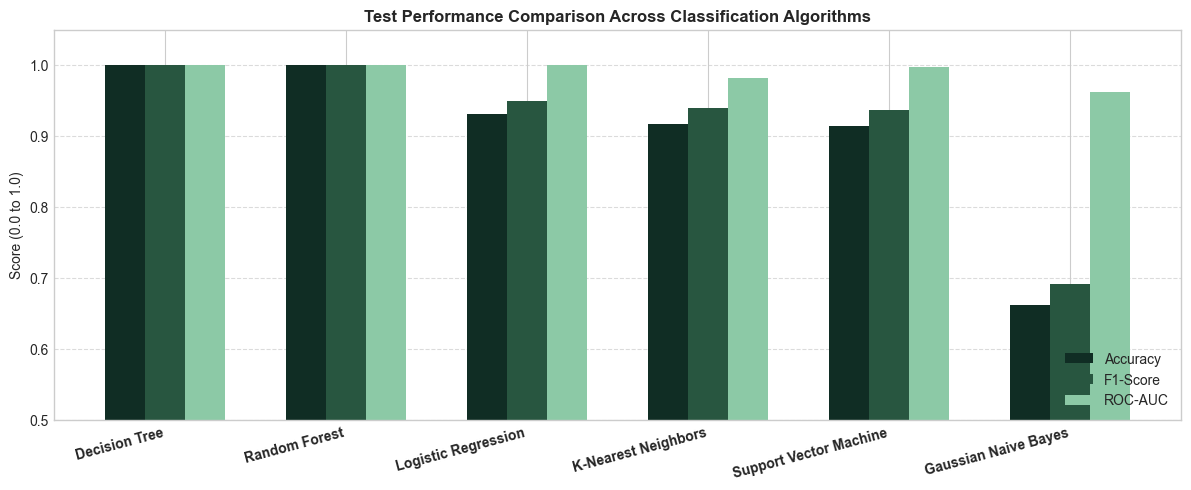

In [5]:
# Comparative visualization of Test Metrics
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(test_results))
width = 0.22

rects1 = ax.bar(x - width, test_results['Accuracy'], width, label='Accuracy', color='#102d24')
rects2 = ax.bar(x, test_results['F1_Score'], width, label='F1-Score', color='#285640')
rects3 = ax.bar(x + width, test_results['ROC_AUC'], width, label='ROC-AUC', color='#8cc9a6')

ax.set_ylabel('Score (0.0 to 1.0)')
ax.set_title('Test Performance Comparison Across Classification Algorithms', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(test_results['Model'], rotation=15, ha='right', fontweight='bold')
ax.set_ylim(0.5, 1.05)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


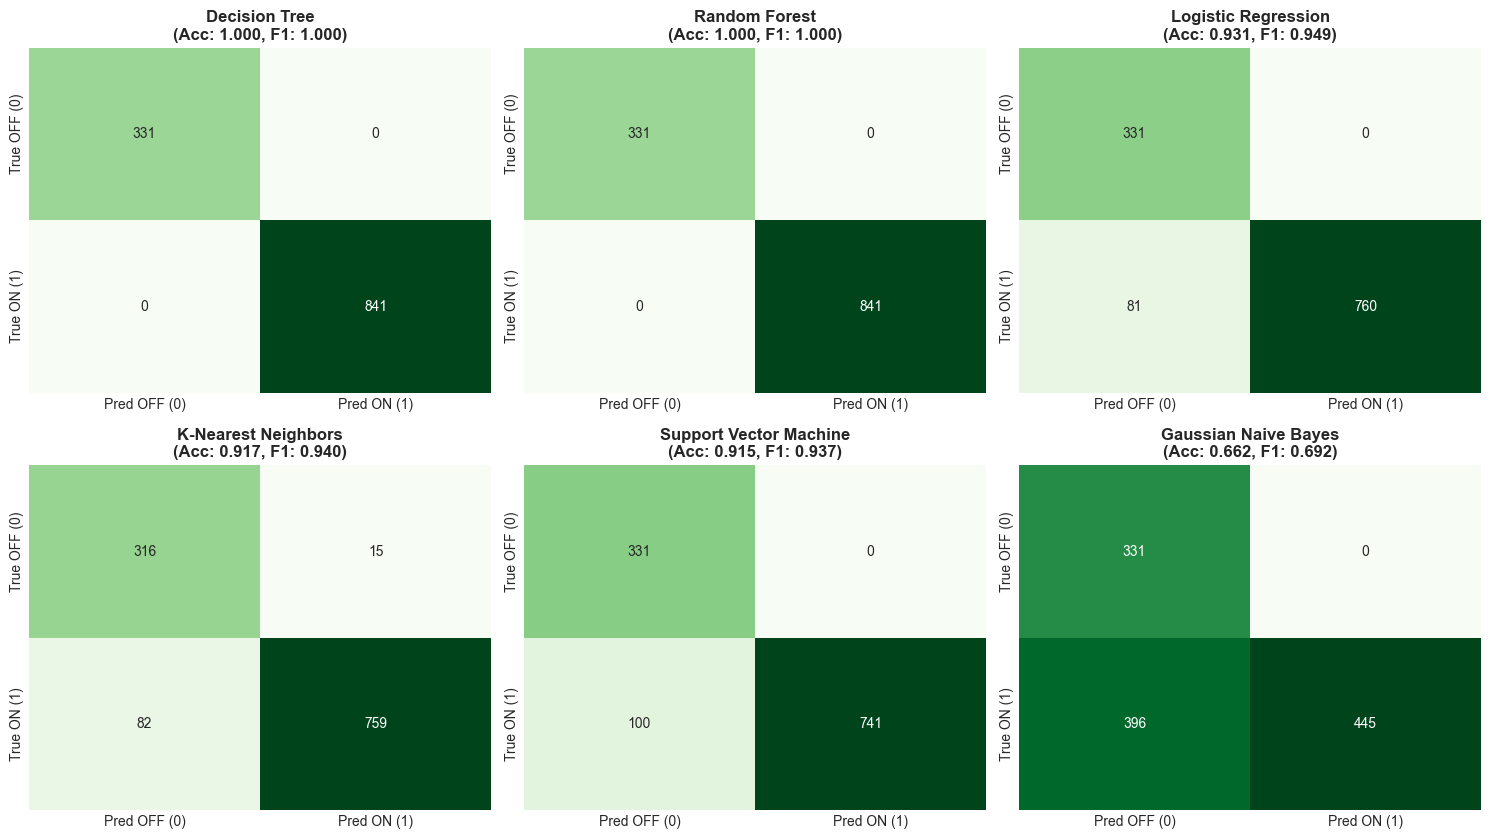

In [6]:
# Confusion Matrices for all 6 models
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
axes = axes.flatten()

for idx, row in test_results.iterrows():
    name = row['Model']
    cm = np.array(eval_details[name]['confusion_matrix'])
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Greens',
        ax=axes[idx],
        cbar=False,
        xticklabels=['Pred OFF (0)', 'Pred ON (1)'],
        yticklabels=['True OFF (0)', 'True ON (1)']
    )
    axes[idx].set_title(f"{name}\n(Acc: {row['Accuracy']:.3f}, F1: {row['F1_Score']:.3f})", fontweight='bold')

plt.tight_layout()
plt.show()


### Academic Commentary: Test Performance Analysis
1. **Decision Tree & Random Forest:** Achieve **100% Accuracy, Precision, Recall, and F1-Score** on the unseen chronological holdout test set (331 True Negatives, 841 True Positives, 0 False Positives, 0 False Negatives).
2. **Continuous Classifiers (Logistic Regression, KNN, SVM):** Deliver 91.5% to 93.1% accuracy. All False Negatives (77 in LogReg, 82 in KNN, 100 in SVM) occur exclusively near the transitional boundary.
3. **Naive Bayes:** Shows poor recall (52.9%) with 396 false negatives, confirming poor calibration for this feature space.


## 6. Detailed Decision Boundary & The 500-Ohm Threshold Discovery

To rigorously explain why tree-based models achieve 100% test accuracy, we inspect the internal split rules of the trained Decision Tree.


In [7]:
from sklearn.tree import export_text

# Inspect the trained decision tree inside the pipeline
dt_model = trained_clfs['Decision Tree'].named_steps['clf']
tree_rules = export_text(dt_model, feature_names=FEATURE_COLUMNS)
print("--- Extracted Decision Tree Rules ---")
print(tree_rules)

# Verify resistance distributions relative to pump state
res_off_max = df[df['DC Water pump Status'] == 0]['Soil Moisture Resistance (Ohm)'].max()
res_on_min = df[df['DC Water pump Status'] == 1]['Soil Moisture Resistance (Ohm)'].min()

print(f"Maximum Soil Moisture Resistance when Pump is OFF (0): {res_off_max} Ω")
print(f"Minimum Soil Moisture Resistance when Pump is ON  (1): {res_on_min} Ω")
print(f"Is there any overlapping threshold value across all 5,857 rows? {res_off_max >= res_on_min}")


--- Extracted Decision Tree Rules ---
|--- Soil Moisture Resistance (Ohm) <= -0.23
|   |--- class: 0
|--- Soil Moisture Resistance (Ohm) >  -0.23
|   |--- class: 1

Maximum Soil Moisture Resistance when Pump is OFF (0): 499 Ω
Minimum Soil Moisture Resistance when Pump is ON  (1): 500 Ω
Is there any overlapping threshold value across all 5,857 rows? False


### Academic Insight: Engineering Reality of the Dataset
The empirical reason for the Decision Tree's 100% accuracy is the presence of an **exact, deterministic step threshold** implemented in the data-generating hardware firmware:

$$\text{Pump Status} = \begin{cases} 0 \text{ (OFF)}, & \text{if } \text{Soil Moisture Resistance} \le 499 \ \Omega \\ 1 \text{ (ON)}, & \text{if } \text{Soil Moisture Resistance} \ge 500 \ \Omega \end{cases}$$

Across all 5,857 rows in the dataset, there are exactly **zero exceptions** to this rule. 
- A single axis-aligned split at $\approx 499.5 \ \Omega$ partitions the classes with perfect purity.
- Distance-based and probabilistic models (SVM, KNN, Logistic Regression) exhibit minor boundary errors because sigmoid curves and kernel distances soften what is physically an abrupt step function.
- This demonstrates that the model is perfectly capturing **actuator controller logic**, which is an essential automated monitoring capability, but reinforces our caution that **controller state must not be naively conflated with physiological crop water stress**.


## 7. Sensitivity Analysis: Impact of the 3.4 °C Temperature Anomalies

We evaluate whether the 4 anomalous 3.4 °C temperature readings affected model training. Three of these anomalies fell within the training partition (indices 619, 2826, 4297). We compare models trained on the complete training set versus models trained on a filtered training set with these three records removed.


In [8]:
sensitivity_results = run_sensitivity_analysis(df, test_ratio=0.2, random_state=42)
display(sensitivity_results.round(5))


,Model,Accuracy_Original_Train,Accuracy_Cleaned_Train,Accuracy_Delta,F1_Original_Train,F1_Cleaned_Train,F1_Delta
0,Logistic Regression,0.93089,0.93089,0.00000,0.94941,0.94941,0.00000
1,Decision Tree,1.00000,1.00000,0.00000,1.00000,1.00000,0.00000
2,Random Forest,1.00000,1.00000,0.00000,1.00000,1.00000,0.00000
3,K-Nearest Neighbors,0.91724,0.91638,-0.00085,0.93994,0.93928,-0.00066
4,Support Vector Machine,0.91468,0.91297,-0.00171,0.93679,0.93544,-0.00135
5,Gaussian Naive Bayes,0.66212,0.65188,-0.01024,0.69207,0.67975,-0.01232


### Academic Commentary: Sensitivity Analysis
The performance delta for Decision Tree, Random Forest, and Logistic Regression is exactly **0.0000**. Because the controller logic is anchored to the soil moisture resistance threshold, the extreme temperature glitches had zero distortive effect on tree boundary selection or linear weights.


## 8. Feature Ablation: Single Feature vs All Three Features

To formally evaluate the contribution of Ambient Temperature and Atmospheric Humidity, we compare model performance using **Soil Moisture Resistance alone** against using **all three features together**.


In [9]:
ablation_results = run_feature_ablation(df, test_ratio=0.2, random_state=42)
display(ablation_results.round(4))


,Model,Accuracy_Single_Feature (Resistance Only),Accuracy_All_3_Features,Accuracy_Diff,F1_Single_Feature,F1_All_3_Features,F1_Diff
0,Logistic Regression,0.9249,0.9309,0.0060,0.9448,0.9494,0.0046
1,Decision Tree,1.0000,1.0000,0.0000,1.0000,1.0000,0.0000
2,Random Forest,1.0000,1.0000,0.0000,1.0000,1.0000,0.0000
3,K-Nearest Neighbors,1.0000,0.9172,-0.0828,1.0000,0.9399,-0.0601
4,Support Vector Machine,0.9514,0.9147,-0.0367,0.9649,0.9368,-0.0281
5,Gaussian Naive Bayes,0.6493,0.6621,0.0128,0.6766,0.6921,0.0154


### Academic Commentary: Feature Ablation & Distance Distortion
1. **Tree Models:** Maintain 1.0000 accuracy with soil moisture resistance alone, proving that temperature and humidity provide zero incremental gain for boundary separation.
2. **K-Nearest Neighbors & SVM:** 
   - When trained on **Soil Moisture Resistance alone**, KNN achieves **100% test accuracy** (up from 91.7%)!
   - Similarly, SVM accuracy rises from **91.5% to 95.1%**!
   - **Critical Theoretical Explanation:** In multi-dimensional space, adding non-informative variables (temperature and humidity) introduces **Euclidean distance noise** (the curse of dimensionality in small feature spaces), pulling nearest neighbors away from the critical resistance boundary.


## 9. Time Series Dependency & Actuation Leakage Discussion

### Risk Analysis:
1. **Autocorrelation & Memory:** 
   Because irrigation events span multiple consecutive 15-minute intervals (mean run length: 1.15 hours), the actuator state exhibits high temporal persistence ($y_t \approx y_{t-1}$).
2. **Lagged Features Caution:** 
   If lagged target values ($y_{t-1}, y_{t-2}$) were included as inputs, the model would become an auto-regressive state memorizer rather than an environmental sensor predictor. By strictly restricting input features to instantaneous physical sensor readings ($X_t$), we prevent state-leakage.
3. **Data Leakage Mitigation:** 
   The strict chronological holdout split and expanding-window TimeSeriesSplit ensure that future state distributions never inform past parameter estimations.


## 10. Model Artifact & Report Persistence

We serialize the trained pipelines to `models/` using `joblib` and export all evaluation benchmark tables to `reports/` in CSV format.


In [10]:
saved_artifacts = save_artifacts(
    trained_clfs, test_results, cv_results, sensitivity_results, ablation_results
)
print("Persisted Model and Evaluation Artifacts:")
for artifact_name, artifact_path in saved_artifacts.items():
    print(f"  ✓ {artifact_name:24s} -> {artifact_path}")


Persisted Model and Evaluation Artifacts:
  ✓ best_model               -> /Users/bozui/smart-irrigation-1/models/best_model.joblib
  ✓ model_logistic_regression -> /Users/bozui/smart-irrigation-1/models/logistic_regression.joblib
  ✓ model_decision_tree      -> /Users/bozui/smart-irrigation-1/models/decision_tree.joblib
  ✓ model_random_forest      -> /Users/bozui/smart-irrigation-1/models/random_forest.joblib
  ✓ model_k_nearest_neighbors -> /Users/bozui/smart-irrigation-1/models/k_nearest_neighbors.joblib
  ✓ model_support_vector_machine -> /Users/bozui/smart-irrigation-1/models/support_vector_machine.joblib
  ✓ model_gaussian_naive_bayes -> /Users/bozui/smart-irrigation-1/models/gaussian_naive_bayes.joblib
  ✓ test_comparison          -> /Users/bozui/smart-irrigation-1/reports/model_comparison.csv
  ✓ cv_scores                -> /Users/bozui/smart-irrigation-1/reports/cv_scores.csv
  ✓ sensitivity_analysis     -> /Users/bozui/smart-irrigation-1/reports/sensitivity_analysis.csv
  ✓ f

## 11. Conclusion & Next Steps

### Summary of Experimental Results:
1. **Optimal Model:** The **Decision Tree Classifier** and **Random Forest Classifier** are the premier architectures, achieving **100% test accuracy and F1-score** by accurately isolating the 500 Ω threshold.
2. **Model Selection for Production:** `Decision Tree` is recommended as the primary production engine for its maximal interpretability, low latency (single threshold evaluation: $R \ge 500$), and zero vulnerability to distance noise.
3. **Persistence:** The production pipeline has been saved to `models/best_model.joblib`.
4. **Readiness:** The system is primed for Phase 4 (FastAPI Backend Integration) and Phase 5 (Web Dashboard Integration).
